In [28]:
type2marker = {
    "Epithelial cell":["S100A2","KRT5","KRT6A","KRT6B"],
    "Stromal cell":["COL3A1","COL1A2","DCN","MMP2"],
    "T cell":["CD2","CD3D","CD3E","CCL5"],
    "B cell":["MS4A1","CD19","CD79A","BLK"],
    "Myeloid cell":["LYZ","C1QA","CD14","FCGR3A"],
    "Endothelial cell":["EGFL7","VWF","PECAM1","ENG"],
    "Muscle cell":["TAGLN","MYH11","ACTG2","MYL9"],
    "Plasma cell":["IGKC","IGHG1","IGHG3","MZB1"]
}

/tmp/ipykernel_422010/2855341212.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expr_markers['cell_type'] = adata.obs['type']
/tmp/ipykernel_422010/2855341212.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expr_markers['cell_type'] = adata.obs['type']


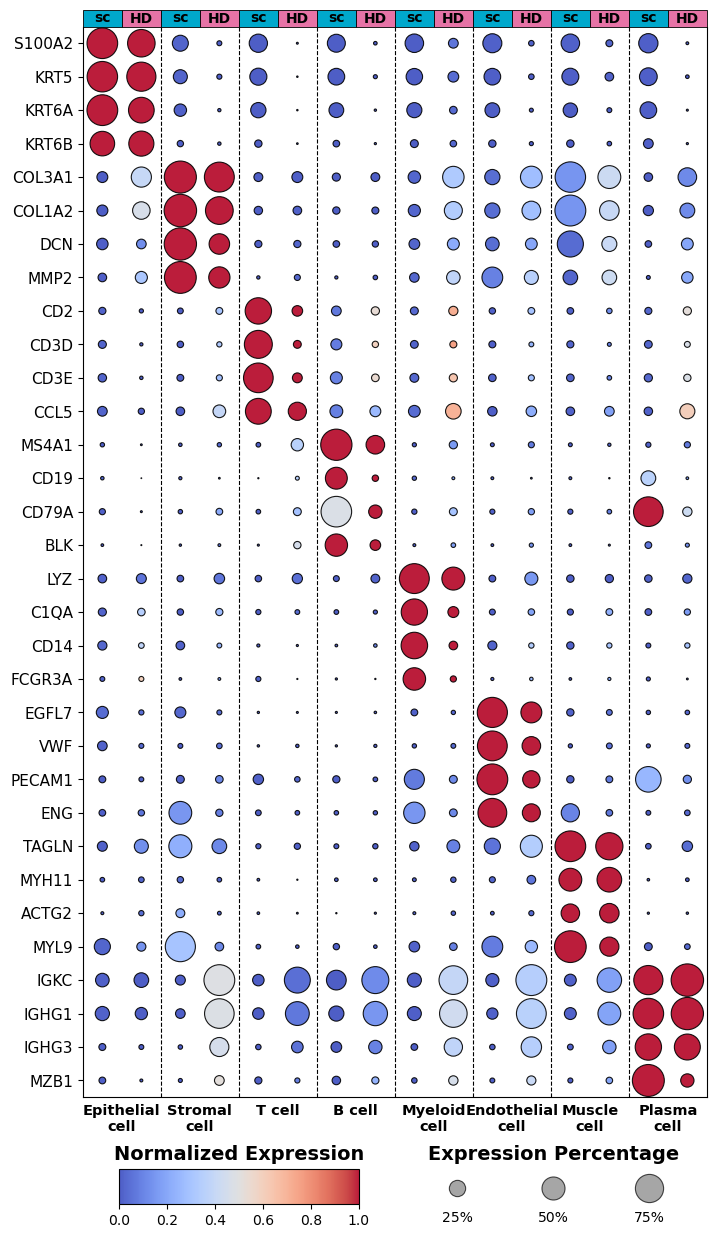

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

# Adjustable parameters
DOT_SIZE_MULTIPLIER = 5.5
PLATFORM_FONT_SIZE = 10
COLOR_MAP = 'coolwarm'
GENE_FONT_SIZE = 11
CELL_TYPE_FONT_SIZE = 10.5

adata_sc = sc.read("./h5ad/adata_sc.h5ad")
adata_HD = sc.read("./h5ad/adata_HD.h5ad")
adata_sc_main = adata_sc[adata_sc.obs['type'].isin(type2marker.keys())].copy()
adata_HD_main = adata_HD[adata_HD.obs['type'].isin(type2marker.keys())].copy()

# Extract all marker genes in the order defined by type2marker
cell_type_order = list(type2marker.keys())
all_markers = []
for cell_type in cell_type_order:
    all_markers.extend(type2marker[cell_type])

# Compute average expression and detection rate per cell type, then apply column-wise normalization
def get_dotplot_data(adata, markers, cell_type_order):
    expr_df = pd.DataFrame(adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X,
                          index=adata.obs_names, columns=adata.var_names)
    expr_markers = expr_df[markers]
    expr_markers['cell_type'] = adata.obs['type']
    
    # Mean expression
    mean_expr = expr_markers.groupby('cell_type', observed=True).mean()
    mean_expr = mean_expr.reindex(cell_type_order).dropna()
    
    # Column-wise min-max normalization
    mean_expr_normalized = mean_expr.copy()
    for gene in mean_expr.columns:
        col_values = mean_expr[gene].values
        min_val = np.min(col_values)
        max_val = np.max(col_values)
        mean_expr_normalized[gene] = (col_values - min_val) / (max_val - min_val)

    # Detection rate (percentage of cells expressing the gene)
    expr_binary = expr_markers[markers] > 0
    expr_binary['cell_type'] = expr_markers['cell_type']
    pct_expr = expr_binary.groupby('cell_type', observed=True).mean() * 100
    pct_expr = pct_expr.reindex(cell_type_order).dropna()
    
    return mean_expr_normalized, pct_expr

# Get data for both datasets
mean_sc, pct_sc = get_dotplot_data(adata_sc_main, all_markers, cell_type_order)
mean_hd, pct_hd = get_dotplot_data(adata_HD_main, all_markers, cell_type_order)

# Create combined DataFrame for plotting
def create_combined_data(mean_sc, pct_sc, mean_hd, pct_hd, cell_type_order, all_markers):
    combined_data = []
    for i, cell_type in enumerate(cell_type_order):
        if cell_type in mean_sc.index and cell_type in mean_hd.index:
            for j, gene in enumerate(all_markers):
                if gene in mean_sc.columns:
                    combined_data.append({
                        'cell_type': cell_type,
                        'gene': gene,
                        'dataset': 'Single Cell',
                        'mean_expression': mean_sc.loc[cell_type, gene],
                        'pct_expression': pct_sc.loc[cell_type, gene],
                        'x_coord': i * 2,
                        'y_coord': j
                    })
            for j, gene in enumerate(all_markers):
                if gene in mean_hd.columns:
                    combined_data.append({
                        'cell_type': cell_type,
                        'gene': gene,
                        'dataset': 'Visium HD',
                        'mean_expression': mean_hd.loc[cell_type, gene],
                        'pct_expression': pct_hd.loc[cell_type, gene],
                        'x_coord': i * 2 + 1,
                        'y_coord': j
                    })
    return pd.DataFrame(combined_data)

combined_df = create_combined_data(mean_sc, pct_sc, mean_hd, pct_hd, cell_type_order, all_markers)

# ==================== Plotting ====================
fig = plt.figure(figsize=(8, 17.845))
ax = fig.add_axes([0.12, 0.22, 0.78, 0.6])  # Main plot area, leaving space at the bottom

# Draw scatter plot (dot plot)
scatter = ax.scatter(
    x=combined_df['x_coord'],
    y=combined_df['y_coord'],
    s=combined_df['pct_expression'] * DOT_SIZE_MULTIPLIER,
    c=combined_df['mean_expression'],
    cmap=COLOR_MAP,
    alpha=0.9,
    edgecolors='black',
    linewidth=0.8
)

# Set y-axis (genes)
ax.set_yticks(range(len(all_markers)))
ax.set_yticklabels(all_markers, fontsize=GENE_FONT_SIZE)
ax.invert_yaxis()

# x-axis range
n_cols = len(cell_type_order) * 2
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(len(all_markers) - 0.5, -0.5)

# Remove unnecessary labels
ax.set_xlabel('')
ax.set_ylabel('')

# Keep only specified spines
for spine in ['bottom', 'left', 'right']:
    ax.spines[spine].set_visible(True)
ax.spines['top'].set_visible(False)

# Remove x-axis ticks; keep y-axis ticks on the left
ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
ax.tick_params(axis='y', which='both', left=True, right=False)

# ========== Top: cell_type labels (outside the top spine of the main plot) ==========
y_top = len(all_markers) + 0.1

for i, cell_type in enumerate(cell_type_order):
    x_center = i * 2 + 0.5
    b = False
    if len(cell_type.split(" ")) > 1:
        tp = cell_type.split(" ")
        if len(tp[0]) > 1:
            cell_type = tp[0] + "\n" + tp[1]
            b = True
    ax.text(x_center + (0.1 if cell_type == "Fibroblast" else 0), y_top + 0.5 if b else y_top, cell_type,
            ha='center', va='bottom',
            fontsize=CELL_TYPE_FONT_SIZE, fontweight='bold',
            transform=ax.transData, clip_on=False, zorder=2)

# ========== Bottom: SC/HD platform labels (inside the main plot,紧贴 the bottom spine) ==========
rect_height_bottom = 0.5
y_bottom = -1

for i, cell_type in enumerate(cell_type_order):
    x_sc_left = i * 2 - 0.5
    x_hd_left = i * 2 + 0.5

    rect_sc = plt.Rectangle((x_sc_left, y_bottom), 1, rect_height_bottom,
                            facecolor='#00A8CC', edgecolor='black', linewidth=0.6,
                            transform=ax.transData, clip_on=False, zorder=1)
    ax.add_patch(rect_sc)
    ax.text(i * 2, y_bottom + rect_height_bottom / 2 + 0.002, 'sc',
            ha='center', va='center', fontsize=PLATFORM_FONT_SIZE, fontweight='bold',
            transform=ax.transData, clip_on=False, zorder=1)

    rect_hd = plt.Rectangle((x_hd_left, y_bottom), 1, rect_height_bottom,
                            facecolor='#E673A6', edgecolor='black', linewidth=0.6,
                            transform=ax.transData, clip_on=False, zorder=1)
    ax.add_patch(rect_hd)
    ax.text(i * 2 + 1, y_bottom + rect_height_bottom / 2 + 0.02, 'HD',
            ha='center', va='center', fontsize=PLATFORM_FONT_SIZE, fontweight='bold',
            transform=ax.transData, clip_on=False, zorder=1)

# ========== Vertical dashed separators between cell types ==========
for i in range(len(cell_type_order) - 1):
    x_pos = (i + 0.75) * 2
    ax.axvline(x=x_pos, ymin=0, ymax=1, linestyle='--', color='black', linewidth=0.8, clip_on=False)

# ========== Bottom legend area: horizontal colorbar + dot size legend ==========
# 1. Horizontal colorbar (Normalized Expression)
cbar_ax = fig.add_axes([0.165, 0.16, 0.30, 0.02])  # [left, bottom, width, height]
cbar = plt.colorbar(scatter, cax=cbar_ax, orientation='horizontal', shrink=0.8, aspect=20)
cbar.set_label('Normalized Expression', fontsize=14, fontweight='bold', labelpad=-60)  # Label above the colorbar
cbar.ax.tick_params(labelsize=10)

# 2. Dot size legend (Expression Percentage)
legend_x_start = 0.45  # Leave some spacing
legend_width = 0.40
legend_height = 0.05
legend_ax = fig.add_axes([legend_x_start, 0.15, legend_width, legend_height])
legend_ax.axis('off')  # Turn off axis

# Define x positions of dots (in axes coordinates, 0~1)
x_positions = [0.345, 0.645, 0.945]  # Three dots, evenly distributed
y_center = 0.38  # Vertical position of dots (0~1)

# Title: use transAxes, centered at the top
legend_ax.text(0.645, y_center + 0.375, 'Expression Percentage', 
               transform=legend_ax.transAxes, fontsize=14, fontweight='bold', 
               ha='center', va='center')

pct_values = [25, 50, 75]
sizes = [p * DOT_SIZE_MULTIPLIER for p in pct_values]

for x, size, pct in zip(x_positions, sizes, pct_values):
    # Draw scatter points using transAxes
    legend_ax.scatter(x, y_center, s=size, c='gray', alpha=0.7, 
                      edgecolors='black', linewidth=0.8,
                      transform=legend_ax.transAxes)  # Key: use axes coordinates
    
    # Add labels below each dot
    legend_ax.text(x, y_center - 0.25, f'{pct}%', 
                   transform=legend_ax.transAxes,
                   fontsize=10, ha='center', va='top')